## Useful scripts for Massvis
1. Stats for fixation numbers and durations
2. GT distribution plotting
3. Saliency evaluation metrics

In [9]:
import numpy as np
import os
import csv
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage
from eval import calculate_metrics

img_path = "/netpool/homes/wangyo/Dataset/Massvis/targets393/targets"
#gt_path = "../../eyetracking/csv_files/fixationsByVis"
gt_path = "../../eyetracking/csv_files/fixationsByVis_5000"

### Stats for fixation numbers and durations

In [21]:
dur = np.zeros((6200,), dtype=int)
num = np.zeros((100,), dtype=int)
for f in os.listdir(gt_path):
    fixs = os.path.join(gt_path, f, 'enc')
    for fix in os.listdir(fixs):
        with open(os.path.join(fixs,fix)) as csvfile:
            cnt = 0
            csv_reader = csv.reader(csvfile,delimiter=',')
            for row in csv_reader:
                i = int(row[3])
                while i > 0:
                    dur[i] += 1
                    i -= 1
                cnt += 1
            j = cnt
            while j > 0:
                num[j] += 1
                j -= 1
print(num)
print(dur)

[   0 6550 6550 6547 6544 6543 6541 6538 6533 6526 6516 6504 6489 6471
 6438 6390 6316 6212 6022 5737 5329 4770 4160 3445 2662 1974 1346  842
  469  257  123   54   26    9    4    1    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]
[     0 147438 147438 ...      0      0      0]


### Probability computation

In [98]:
e_num = 35
res_num = (num[e_num] - num[e_num+1]) / num[1]
print('probability of fixation number = %d: %f'%(e_num, res_num))
e_dur = 2
interval = 98
res_dur = (dur[e_dur] - dur[e_dur+interval]) / dur[1]
print('probability of duration between %d and %d: %f'%(e_dur, e_dur+interval, res_dur))


probability of fixation number = 35: 0.000153
probability of duration between 2 and 100: 0.000000


## Element Duration

array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,  12.,  82.,  10.,  52.,   8.,  76.,  12.,  66.,  16.,
        58.,   8.,  70.,  26.,  74.,  26.,  88.,  16.,  78.,  16.,  80.,
        18., 126.,  18., 116.,  20., 106.,  32., 146.,  16., 122.,  20.,
       156.,  34., 148.,  32., 148.,  20., 160.,  16., 192.,  36., 182.,
        34., 176.,  24., 160.,  38., 174.,  28., 21

### Fixation distributions (resized coords)

In [10]:
sum_map =np.zeros((1000,1000), dtype=float)
for f in os.listdir(gt_path):
    fixs = os.path.join(gt_path, f, 'enc')
    for fix in os.listdir(fixs):
        with open(os.path.join(fixs,fix)) as csvfile:
            im = Image.open(os.path.join(img_path, f + '.png'))
            w, h = im.size
            csv_reader = csv.reader(csvfile,delimiter=',')
            for row in csv_reader:
                if int(row[0]) < 2: continue
                sum_map[int(float(row[1]) * 1000 / w), int(float(row[2]) * 1000 / h)] += 1

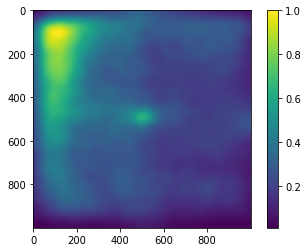

In [11]:
sum_map = ndimage.filters.gaussian_filter(sum_map, [19, 19])
heatmap = sum_map/float(np.max(sum_map))
fig, ax = plt.subplots()
im = ax.imshow(heatmap)
fig.colorbar(im)
plt.show()

### Fixation distributions (Centered coords)

In [22]:
sum_map =np.zeros((1000,1000), dtype=float)
for f in os.listdir(gt_path):
    fixs = os.path.join(gt_path, f, 'enc')
    for fix in os.listdir(fixs):
        with open(os.path.join(fixs,fix)) as csvfile:
            im = Image.open(os.path.join(img_path, f + '.png'))
            w, h = im.size
            csv_reader = csv.reader(csvfile,delimiter=',')
            for row in csv_reader:
                if int(row[0]) > 2: continue
                sum_map[int(float(row[1]) + 500 - w / 2), int(float(row[2]) + 500 - h / 2)] += 1

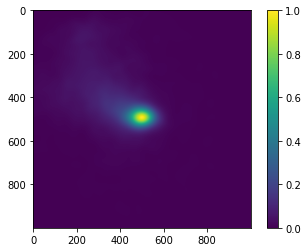

In [23]:
sum_map = ndimage.filters.gaussian_filter(sum_map, [19, 19])
heatmap = sum_map/float(np.max(sum_map))
fig, ax = plt.subplots()
im = ax.imshow(heatmap)
fig.colorbar(im)
plt.show()

## Saliency map Evaluation ##

In [78]:
salmap_path = "/path/to/your/maps/"

salmap_paths = [os.path.join(salmap_path, f) for f in os.listdir(salmap_path)]

gt_root_path = "/netpool/homes/wangyo/Dataset/Massvis/targets393/GT/val"
gt_duration = '5000'
gt_salmap_path = os.path.join(gt_root_path,'heatmaps_accum', gt_duration)
gt_fixmap_path = os.path.join(gt_root_path,'fix_maps_accum', gt_duration)

In [79]:
all_m = {}

for f in os.listdir(gt_salmap_path):
    gt_salmap = mpimg.imread(os.path.join(gt_salmap_path, f))
    gt_fixmap = mpimg.imread(os.path.join(gt_fixmap_path, f))
    pred_salmap = mpimg.imread(os.path.join(salmap_path, f))
    m = calculate_metrics(pred_salmap, gt_map=gt_salmap, gt_fix_map=gt_fixmap)
    
    for k,v in m.items():
        all_m[k] = all_m.get(k, []) + v # append list to list or int to int

In [80]:
print("Overall metrics:")
for k,v in all_m.items():
    print("\t", k,':', np.mean(v))

Overall metrics:
	 R2 : -2.820343973058643
	 RMSE : 0.26399022
	 CC : 0.4734227474385637
	 CC (saliconeval) : 0.4734227480912292
	 KL : 0.9410989
	 SIM : 0.52644366
	 NSS : 0.8276453


## Saliency Metrics

In [22]:
salmap_path = "/path/to/your/maps/"
gt_salmap_path = "/path/to/ground/truth/maps/"


all_m1 = {}

for imname in os.listdir(gt_salmap_path):
    imsuf = imname.split('.')[0]
    salmap_file = salmap_path + imname
    #salmap_file = salmap_path + imsuf + '_5000.png'
    gt_salmap_file = os.path.join(gt_salmap_path, imname)
    #if not '5000' in imsuf: continue
    if not os.path.exists(salmap_file): continue
    with Image.open(salmap_file) as pred_salmap:
        gt_salmap = Image.open(gt_salmap_file)
        w,h = gt_salmap.size
        pred_salmap = pred_salmap.convert("L")
        pred_salmap = pred_salmap.resize((w,h))
        pred_salmap = np.array(pred_salmap)
        pred_salmap = pred_salmap / np.max(pred_salmap) * 255

        gt_salmap = gt_salmap.convert("L")
        gt_salmap = np.array(gt_salmap)

    
        m = calculate_metrics(pred_salmap, gt_map=gt_salmap)

        for k,v in m.items():
            all_m1[k] = all_m1.get(k, []) + v # append list to list or int to int


In [23]:
print("Overall metrics:")
for k,v in all_m1.items():
    print("\t", k,':', np.mean(v))

Overall metrics:
	 R2 : -1.3372007318905421
	 RMSE : 0.1827404
	 CC : 0.046961930304798526
	 CC (saliconeval) : 0.04696193033203431
	 KL : 1.7663038
	 SIM : 0.29781136
